# 🚀 Модуль 3. Урок 3. Слияния датасетов (merge, concat) и продвинутая агрегация .groupby().agg()

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_03_python/lesson_03_pandas_aggregations_merge.ipynb)

## 📌 Бизнес-контекст и методология
Агрегация в Pandas через `.groupby().agg()` позволяет за один проход рассчитать комплексный скоринг сегментов:
суммарную выручку, количество активных аккаунтов, средний чек, медианный NPS и уровень оттока.
Объединение таблиц (`pd.merge`) является прямым аналогом SQL JOIN, и правильный выбор типа соединения (`inner`, `left`, `outer`) защищает от потери когорт пользователей.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

saas_path = ensure_dataset("saas_users.csv", subfolder="raw")
df_saas = pd.read_csv(saas_path)
print(f"🟢 Датасет saas_users успешно загружен: {df_saas.shape[0]} строк, {df_saas.shape[1]} колонок")

🟢 Датасет saas_users успешно загружен: 2000 строк, 12 колонок


## 🔍 Разбор механики и демонстрация на реальных данных
Сформируем комплексную аналитическую сводку по индустриям:
- Общий объем выручки (`sum`)
- Средний MRR (`mean`)
- Средний NPS-скор (`mean`)
- Доля оттока Churn Rate (`mean`)

In [2]:
# Демонстрация: Многомерная агрегация через .groupby().agg()
industry_summary = df_saas.groupby('industry').agg(
    total_users=('user_id', 'count'),
    total_mrr=('mrr', 'sum'),
    avg_mrr=('mrr', 'mean'),
    churn_rate=('is_churned', 'mean'),
    avg_nps=('nps_score', 'mean')
).reset_index()

industry_summary['churn_rate_pct'] = industry_summary['churn_rate'] * 100
display(industry_summary.round(2))

,industry,total_users,total_mrr,avg_mrr,churn_rate,avg_nps,churn_rate_pct
0,E-commerce,275,21425.0,77.91,0.18,8.46,17.82
1,Edtech,280,22240.0,79.43,0.16,8.23,16.43
2,Fintech,276,21034.0,76.21,0.18,8.36,17.75
3,Healthtech,303,24547.0,81.01,0.17,8.37,16.50
4,Logistics,298,22422.0,75.24,0.15,8.35,15.44
5,Marketing Agency,311,26409.0,84.92,0.15,8.32,15.43
6,SaaS B2B,257,19933.0,77.56,0.19,8.33,18.68


## 📊 Визуализация бизнес-кейса: Матрица «Доходность vs Отток» по индустриям
Построим двумерную карту риска для руководителей клиентского сервиса (CSM): ось X — средний MRR, ось Y — уровень оттока, размер пузыря — суммарный доход.

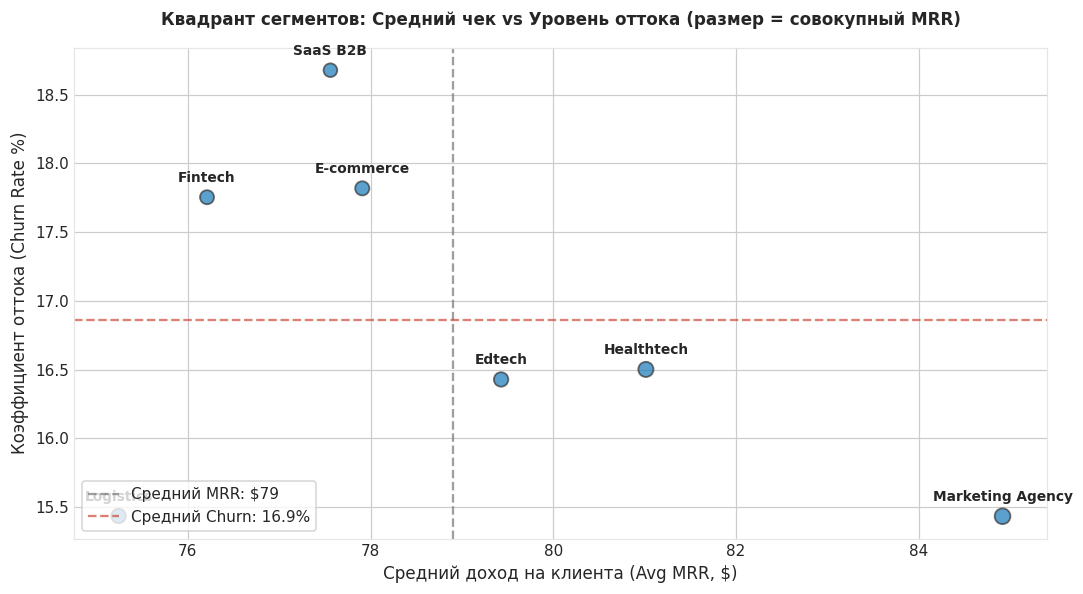

In [3]:
# Построение квадранта доходности и рисков
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=110)

scatter = ax.scatter(industry_summary['avg_mrr'], industry_summary['churn_rate_pct'],
                     s=industry_summary['total_mrr'] / 250, c=PRIMARY, alpha=0.7, 
                     edgecolor='#333333', linewidth=1.2)

# Средние линии квадранта
mean_mrr = industry_summary['avg_mrr'].mean()
mean_churn = industry_summary['churn_rate_pct'].mean()

ax.axvline(mean_mrr, color=SECONDARY, linestyle='--', alpha=0.7, label=f'Средний MRR: ${mean_mrr:.0f}')
ax.axhline(mean_churn, color=ALERT, linestyle='--', alpha=0.7, label=f'Средний Churn: {mean_churn:.1f}%')

# Подписи точек
for _, row in industry_summary.iterrows():
    ax.annotate(row['industry'], (row['avg_mrr'], row['churn_rate_pct']),
                xytext=(0, 10), textcoords="offset points", ha='center', fontweight='bold', fontsize=9)

ax.set_title("Квадрант сегментов: Средний чек vs Уровень оттока (размер = совокупный MRR)", fontsize=11, fontweight='bold', pad=15)
ax.set_xlabel("Средний доход на клиента (Avg MRR, $)", fontsize=11)
ax.set_ylabel("Коэффициент оттока (Churn Rate %)", fontsize=11)
ax.legend(loc='lower left', frameon=True, facecolor='#ffffff')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Агрегация по тарифам и расчет доли выручки
Сгруппируйте `df_saas` по `plan` и посчитайте суммарный MRR, количество пользователей и среднее количество мест (`active_seats`). Рассчитайте долю выручки каждого плана в процентах.

In [4]:
### ВАШ КОД ЗДЕСЬ
plan_summary = df_saas.groupby('plan').agg(
    users=('user_id', 'count'),
    total_mrr=('mrr', 'sum'),
    avg_seats=('active_seats', 'mean')
).reset_index()

plan_summary['revenue_share_pct'] = (plan_summary['total_mrr'] / plan_summary['total_mrr'].sum()) * 100
display(plan_summary.round(2))

assert not plan_summary.empty, "Сводка не должна быть пустой"
assert np.isclose(plan_summary['revenue_share_pct'].sum(), 100.0), "Сумма долей должна равняться 100%"
print("✅ Тест успешно пройден: агрегация и долевые расчеты верны!")

,plan,users,total_mrr,avg_seats,revenue_share_pct
0,Enterprise,212,63388.0,13.45,40.12
1,Professional,611,60489.0,13.69,38.28
2,Starter,1177,34133.0,13.31,21.60


✅ Тест успешно пройден: агрегация и долевые расчеты верны!


### 💡 Паттерн именованных агрегаций
Используйте именованный синтаксис `total_mrr=('mrr', 'sum')` вместо `agg({'mrr': ['sum', 'mean']})`. Это сразу создает плоский индекс колонок и исключает проблемы с `MultiIndex`.